In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/fashion_shirts/Kemeja
!pwd

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/fashion_shirts/Kemeja
/content/drive/MyDrive/fashion_shirts/Kemeja


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cv2

In [ ]:
import tensorflow as tf
from tensorflow import keras

In [ ]:
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [ ]:
fashion_mnist = tf.keras.datasets.fashion_mnist
(X_train_original, y_train_original), (X_test, y_test) = fashion_mnist.load_data()

In [ ]:
shirt_directory = "/content/drive/MyDrive/fashion_shirts/Kemeja"

In [ ]:
# Process shirt images
def process_shirt_images(directory_path, label=6):  # Class 6 is "Shirt" in Fashion MNIST
    processed_images = []
    labels = []
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')

    # Get all image files
    image_files = [f for f in os.listdir(directory_path) if f.lower().endswith(valid_extensions)]

    print(f"Found {len(image_files)} images in the directory")

    for filename in image_files:
        try:
            image_path = os.path.join(directory_path, filename)
            # Read image
            img = cv2.imread(image_path)

            if img is None:
                print(f"Warning: Could not read image {filename}")
                continue

            # Convert to grayscale
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

            # Resize to 28x28
            resized = cv2.resize(gray, (28, 28))

            # Add to our collection
            processed_images.append(resized)
            labels.append(label)
        except Exception as e:
            print(f"Error processing {filename}: {e}")

    return np.array(processed_images), np.array(labels)

In [ ]:
# Process your shirt images
print("Processing shirt images...")
new_shirt_images, new_shirt_labels = process_shirt_images(shirt_directory)
print(f"Successfully processed {len(new_shirt_images)} images")

Processing shirt images...
Found 501 images in the directory
Successfully processed 501 images


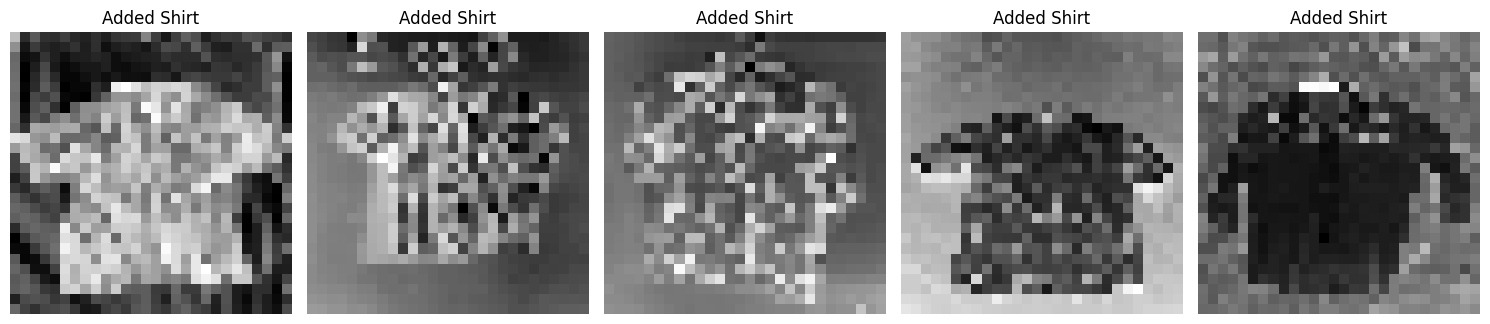

In [ ]:
# Visualize a sample of your processed images
if len(new_shirt_images) > 0:
    plt.figure(figsize=(15, 4))
    plotnumber = 1

    for i in range(min(5, len(new_shirt_images))):
        if plotnumber <= 5:
            ax = plt.subplot(1, 5, plotnumber)
            plt.imshow(new_shirt_images[i], cmap='binary')
            plt.axis('off')
            plt.title("Added Shirt")

        plotnumber += 1

    plt.tight_layout()
    plt.show()


In [ ]:
# Combine with original dataset
X_train_combined = np.concatenate((X_train_original, new_shirt_images))
y_train_combined = np.concatenate((y_train_original, new_shirt_labels))

print(f"Original training set: {X_train_original.shape[0]} images")
print(f"Added shirt images: {new_shirt_images.shape[0]} images")
print(f"Combined training set: {X_train_combined.shape[0]} images")

Original training set: 60000 images
Added shirt images: 501 images
Combined training set: 60501 images


In [ ]:
# Now continue with your original code flow but using the combined dataset
X_train, X_test = X_train_combined, X_test
y_train = y_train_combined

In [ ]:
# Display shapes (keeping your original code)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((60501, 28, 28), (10000, 28, 28), (60501,), (10000,))

In [ ]:
# Display data types (keeping your original code)
X_train.dtype, X_test.dtype, y_train.dtype, y_test.dtype

(dtype('uint8'), dtype('uint8'), dtype('int64'), dtype('uint8'))

In [ ]:
# Split validation set and normalize (slightly adjusted to account for combined dataset)
X_valid, X_train = X_train[:4000], X_train[4000:] / 255
y_valid, y_train = y_train[:4000], y_train[4000:]
X_test = X_test / 255

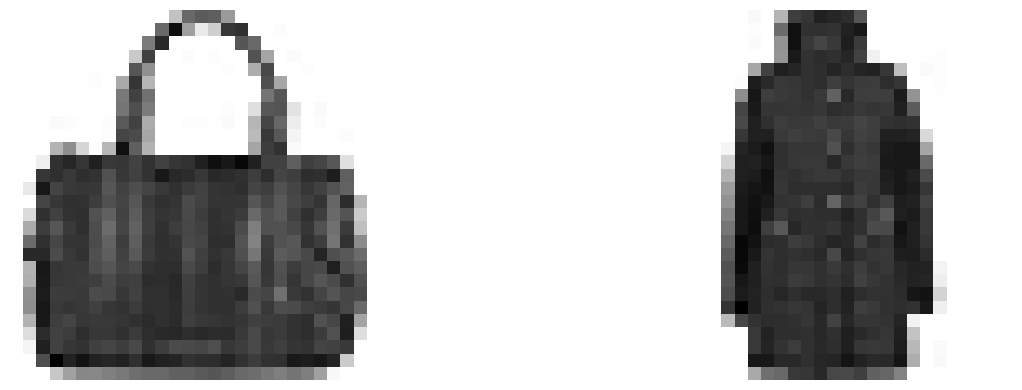

In [ ]:
# Display sample images (your original code)
plt.figure(figsize = (15, 4))
plotnumber = 1

for i in range(2):
    if plotnumber <= 2:
        ax = plt.subplot(1, 2, plotnumber)
        plt.imshow(X_train[i], cmap = 'binary')
        plt.axis('off')

    plotnumber += 1

plt.tight_layout()
plt.show()

In [ ]:
# Class names (your original code)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]


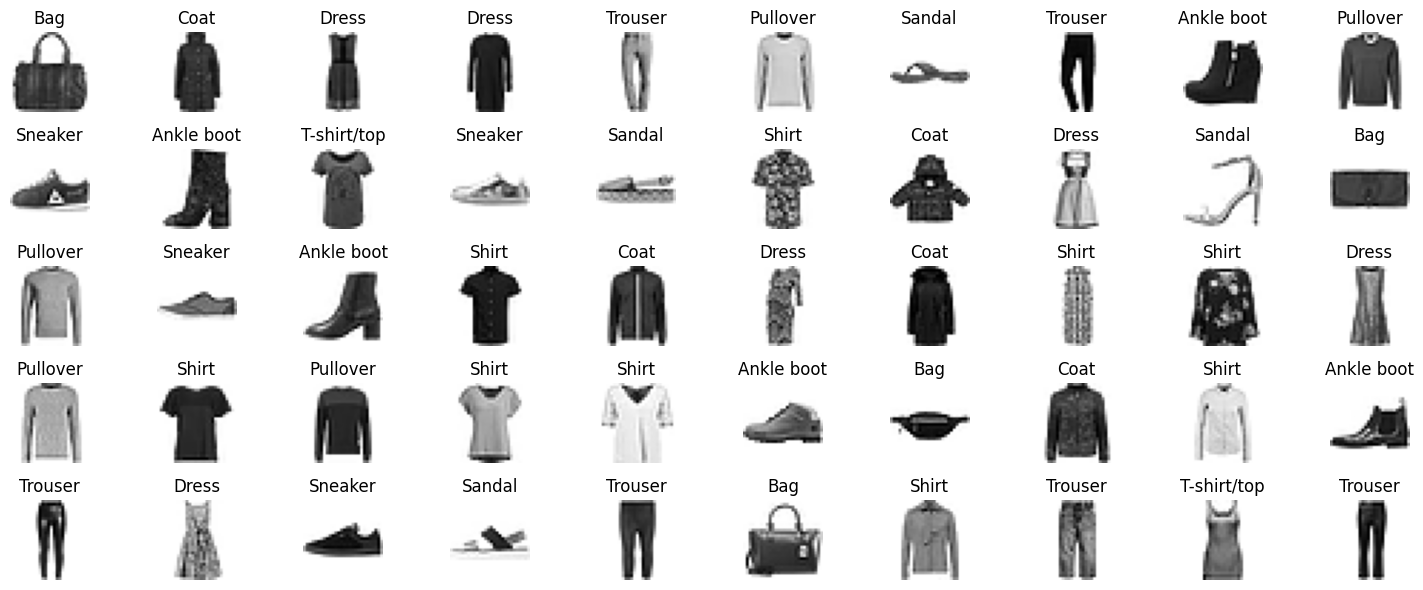

In [ ]:
# Display multiple images with labels (your original code)
plt.figure(figsize = (15, 6))
plotnumber = 1

for i in range(51):
    if plotnumber <= 50:
        ax = plt.subplot(5, 10, plotnumber)
        plt.imshow(X_train[i], cmap = 'binary')
        plt.axis('off')
        plt.title(class_names[y_train[i]], fontdict = {'fontsize'  : 12, 'color' : 'black'})

    plotnumber += 1

plt.tight_layout()
plt.show()

In [ ]:
# Reshape for the ANN layers
X_train = X_train.reshape(X_train.shape[0], 28, 28)
X_valid = X_valid.reshape(X_valid.shape[0], 28, 28)
X_test = X_test.reshape(X_test.shape[0], 28, 28)

# Build the model with ANN first, then LSTM
model = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[28, 28]), # Flatten for initial ANN layers
    keras.layers.Dense(100, activation='relu'),  # ANN layer
    keras.layers.Dense(392, activation='relu'),   # ANN layer #Changed this to 392 (28*14)

    keras.layers.Reshape((28, 14)),           # Reshape for LSTM input #Changed this to (28, 14)
    keras.layers.LSTM(128),                   # LSTM layer

    keras.layers.Dense(50, activation='relu'),  # Dense layers after LSTM
    keras.layers.Dense(20, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 392)                 │          39,592 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape (Reshape)                    │ (None, 28, 14)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 128)                 │          73,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 50)                  │           6,450 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 20)                  │           1,020 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             210 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 198,988 (777.30 KB)

 Trainable params: 198,988 (777.30 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Build model (your original code)
model = keras.models.Sequential([
    keras.layers.Flatten(input_shape = [28, 28]),
    keras.layers.Dense(100, activation = 'relu'),
    keras.layers.Dense(70, activation = 'relu'),
    keras.layers.Dense(50, activation = 'relu'),
    keras.layers.Dense(20, activation = 'relu'),
    keras.layers.Dense(10, activation = 'softmax')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 100)                 │          78,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 70)                  │           7,070 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 50)                  │           3,550 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 20)                  │           1,020 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             210 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 90,350 (352.93 KB)

 Trainable params: 90,350 (352.93 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile model
model.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              optimizer=tf.keras.optimizers.Adam(),
              metrics=['accuracy'])

# Train model with early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)
model_history = model.fit(X_train, y_train,
                          validation_data=(X_valid, y_valid),
                          epochs=50,
                          callbacks=[early_stopping])

Epoch 1/50
1766/1766 ━━━━━━━━━━━━━━━━━━━━ 79s 42ms/step - accuracy: 0.6986 - loss: 0.8270 - val_accuracy: 0.6963 - val_loss: 0.9948
Epoch 2/50
1766/1766 ━━━━━━━━━━━━━━━━━━━━ 79s 41ms/step - accuracy: 0.8517 - loss: 0.4064 - val_accuracy: 0.7380 - val_loss: 0.7838
Epoch 3/50
1766/1766 ━━━━━━━━━━━━━━━━━━━━ 82s 41ms/step - accuracy: 0.8683 - loss: 0.3586 - val_accuracy: 0.7940 - val_loss: 0.6330
Epoch 4/50
1766/1766 ━━━━━━━━━━━━━━━━━━━━ 81s 40ms/step - accuracy: 0.8790 - loss: 0.3298 - val_accuracy: 0.8127 - val_loss: 0.5513
Epoch 5/50
1766/1766 ━━━━━━━━━━━━━━━━━━━━ 73s 41ms/step - accuracy: 0.8827 - loss: 0.3140 - val_accuracy: 0.8075 - val_loss: 0.6440
Epoch 6/50
1766/1766 ━━━━━━━━━━━━━━━━━━━━ 76s 43ms/step - accuracy: 0.8908 - loss: 0.2933 - val_accuracy: 0.8173 - val_loss: 0.5536
Epoch 7/50
1766/1766 ━━━━━━━━━━━━━━━━━━━━ 78s 41ms/step - accuracy: 0.8962 - loss: 0.2761 - val_accuracy: 0.8090 - val_loss: 0.5765
Epoch 8/50
1766/1766 ━━━━━━━━━━━━━━━━━━━━ 73s 41ms/step - accuracy: 0.8997 -

In [ ]:
# Evaluate model (your original code)
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8844 - loss: 0.3264


[0.3260030150413513, 0.8833000063896179]

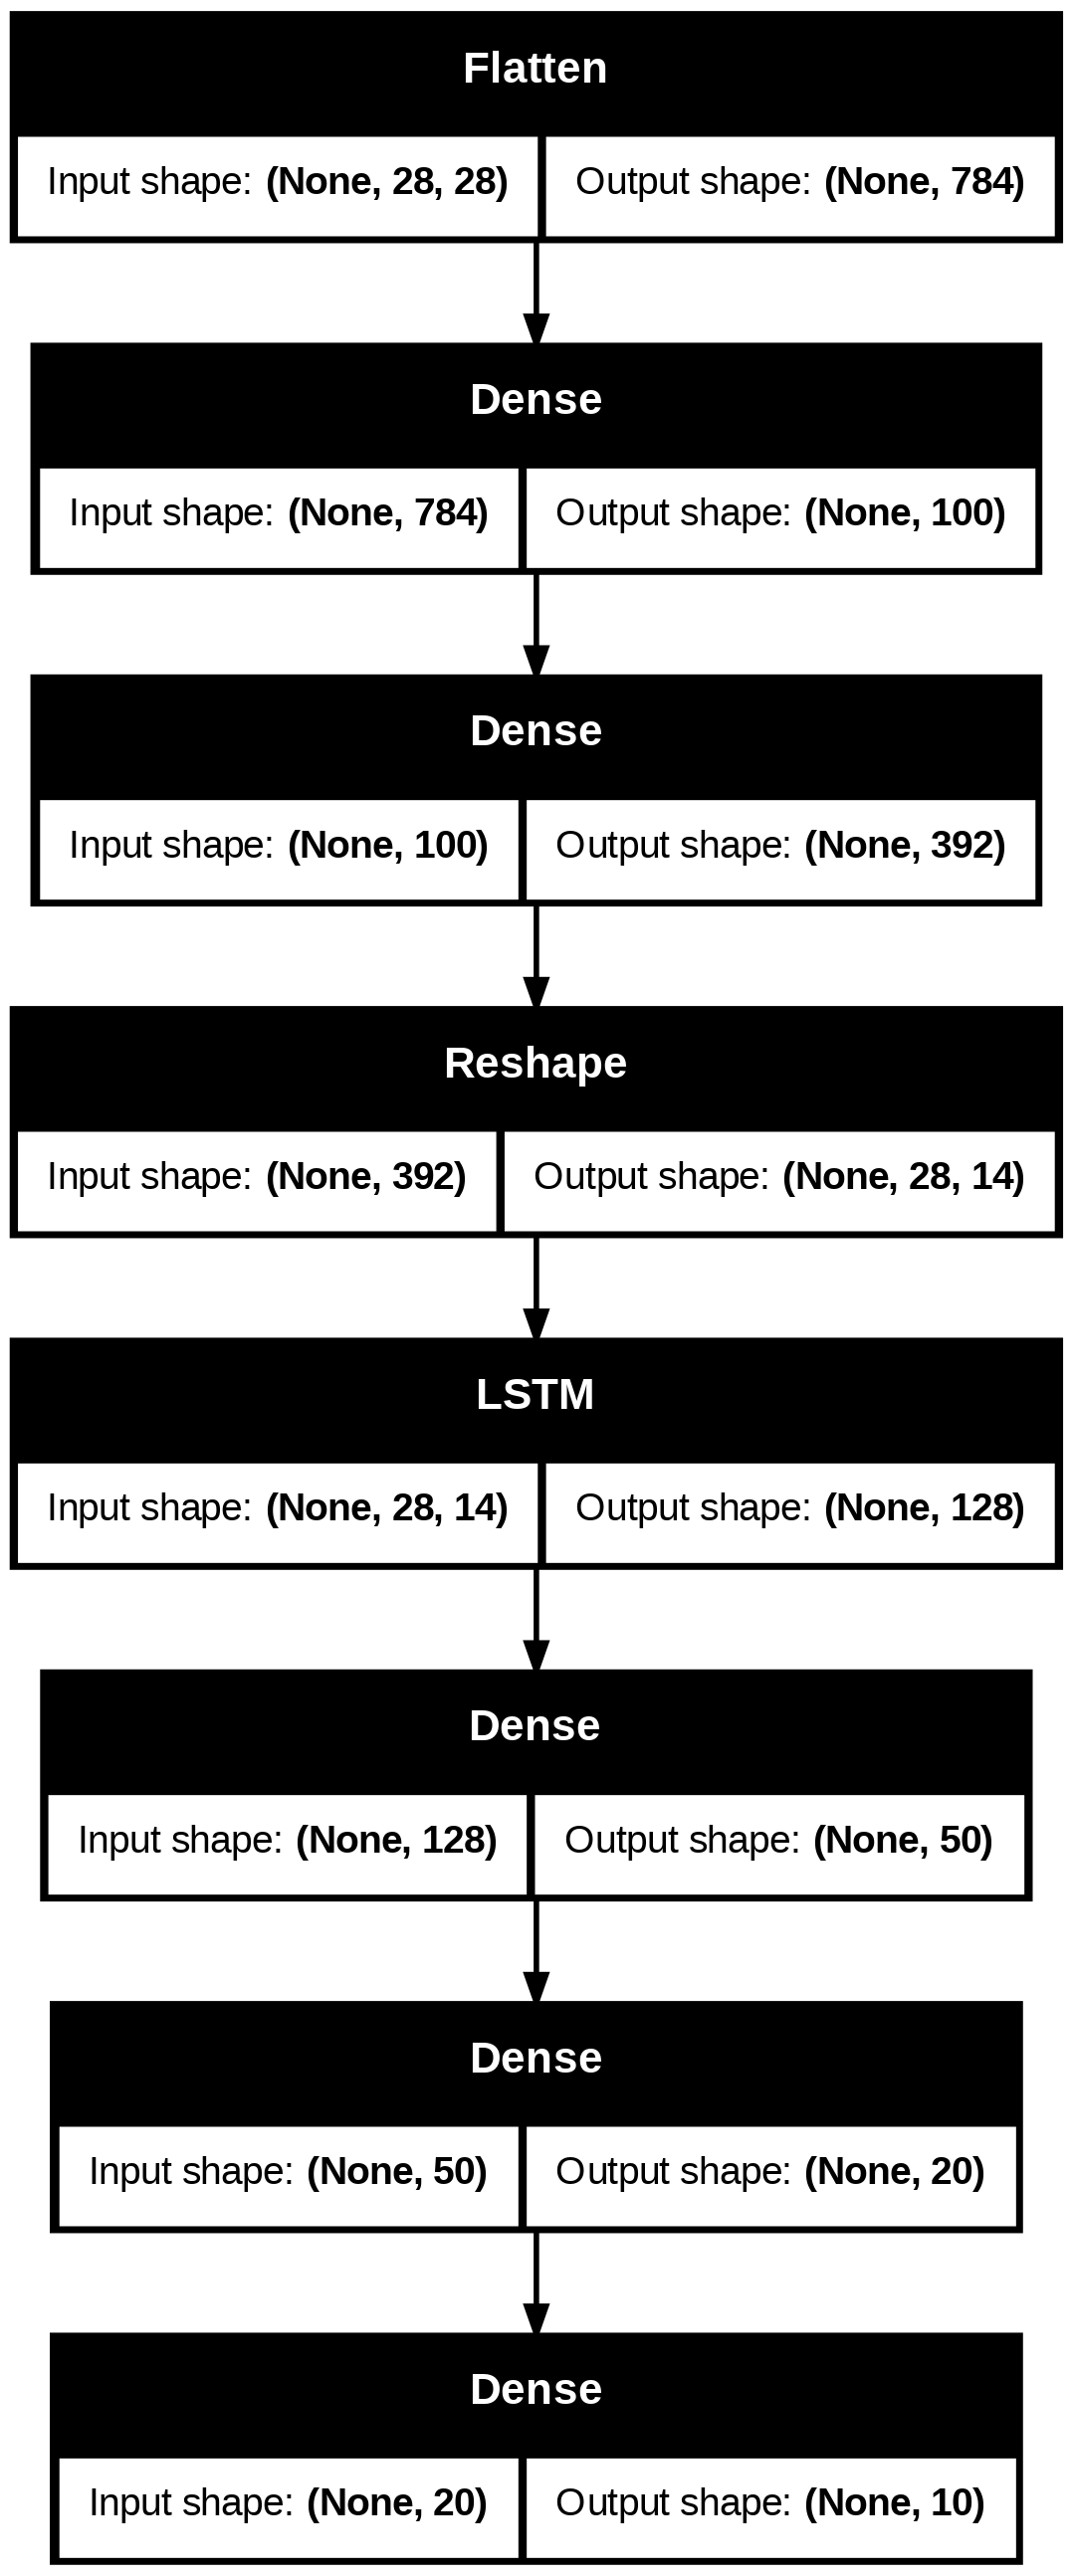

In [ ]:
# Plot model architecture (your original code)
from tensorflow.keras.utils import plot_model
plot_model(model, show_shapes = True)

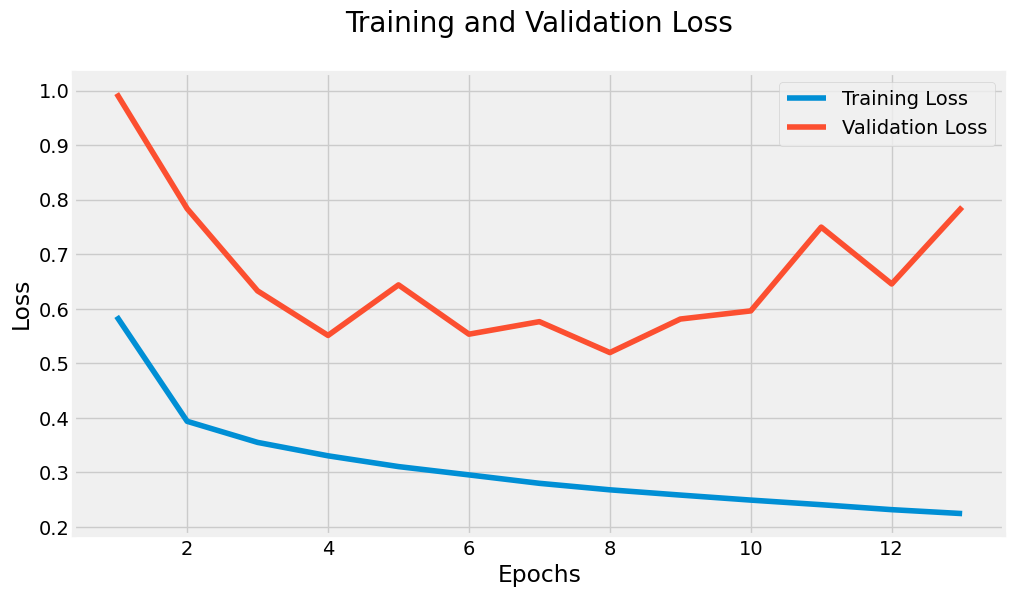

In [ ]:
# Plot training loss (your original code with the fix you provided)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize = (12, 6))
plt.style.use('fivethirtyeight')

train_loss = model_history.history['loss']
val_loss = model_history.history['val_loss']
# Fix: Adjust epoch range to match the actual number of epochs trained
epoch = range(1, len(train_loss) + 1)

# The lineplot function with keyword arguments
sns.lineplot(x=epoch, y=train_loss, label = 'Training Loss')
sns.lineplot(x=epoch, y=val_loss, label = 'Validation Loss')

plt.title('Training and Validation Loss\n')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc = 'best')
plt.show()

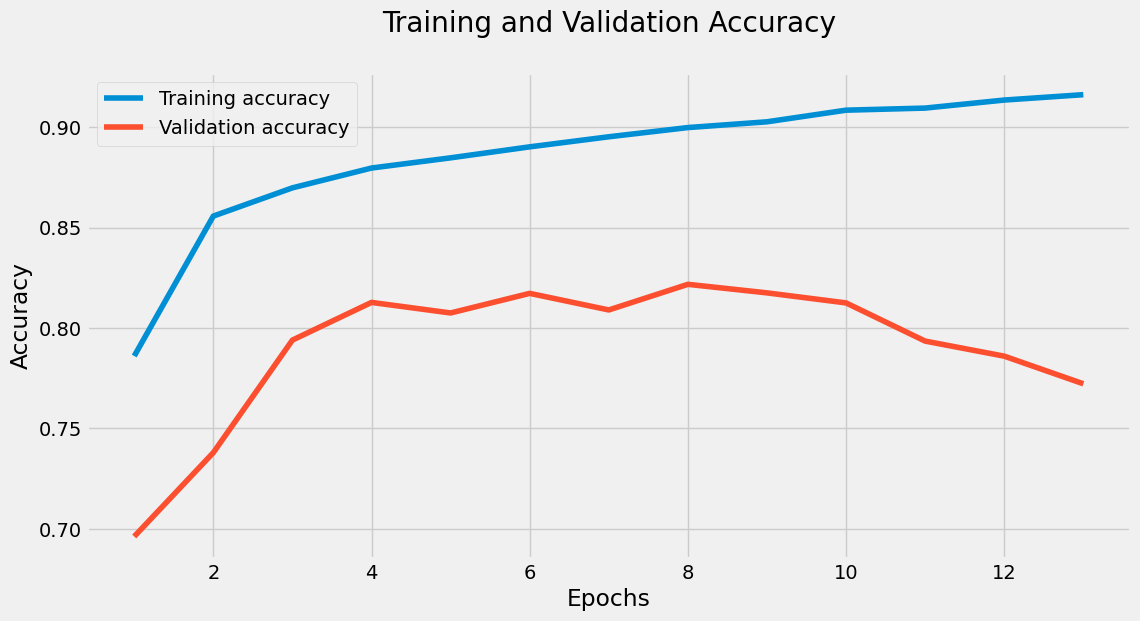

In [ ]:
# Plot training accuracy (your original code with the fix)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize = (12, 6))

train_acc = model_history.history['accuracy']
val_acc = model_history.history['val_accuracy']
# Fix: Adjust epoch range to match the actual number of epochs trained
epoch = range(1, len(train_acc) + 1)

# The lineplot function with keyword arguments
sns.lineplot(x=epoch, y=train_acc, label = 'Training accuracy')
sns.lineplot(x=epoch, y=val_acc, label = 'Validation accuracy')

plt.title('Training and Validation Accuracy\n')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc = 'best')
plt.show()

In [ ]:
# Predictions (your original code)
y_probs = model.predict(X_test)
y_preds = y_probs.argmax(axis = 1)

y_preds[:100]

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step


array([9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5, 5, 3, 4, 1, 2, 2, 8, 0, 2, 5,
       7, 5, 1, 2, 6, 0, 9, 4, 8, 8, 3, 3, 8, 0, 7, 5, 7, 9, 0, 1, 6, 9,
       6, 7, 2, 1, 2, 6, 4, 2, 5, 8, 2, 2, 8, 4, 8, 0, 7, 7, 8, 5, 1, 1,
       6, 4, 7, 8, 7, 0, 2, 6, 2, 3, 1, 2, 8, 4, 1, 8, 5, 9, 5, 0, 3, 2,
       0, 2, 5, 3, 6, 7, 1, 8, 0, 1, 2, 2])

In [ ]:
# Confusion matrix function (your original code)
import itertools
from sklearn.metrics import confusion_matrix

# Your function for plotting confusion matrix
def make_confusion_matrix(y_true, y_pred, classes=None, figsize=(10, 10), text_size=15):
  """Makes a labelled confusion matrix comparing predictions and ground truth labels.

  If classes is passed, confusion matrix will be labelled, if not, integer class values
  will be used.

  Args:
    y_true: Array of truth labels (must be same shape as y_pred).
    y_pred: Array of predicted labels (must be same shape as y_true).
    classes: Array of class labels (e.g. string form). If `None`, integer labels are used.
    figsize: Size of output figure (default=(10, 10)).
    text_size: Size of output figure text (default=15).

  Returns:
    A labelled confusion matrix plot comparing y_true and y_pred.

  Example usage:
    make_confusion_matrix(y_true=test_labels, # ground truth test labels
                          y_pred=y_preds, # predicted labels
                          classes=class_names, # array of class label names
                          figsize=(15, 15),
                          text_size=10)
  """
  # Create the confustion matrix
  cm = confusion_matrix(y_true, y_pred)
  cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] # normalize it
  n_classes = cm.shape[0] # find the number of classes we're dealing with

  # Plot the figure and make it pretty
  fig, ax = plt.subplots(figsize=figsize)
  cax = ax.matshow(cm, cmap=plt.cm.Blues) # colors will represent how 'correct' a class is, darker == better
  fig.colorbar(cax)

  # Are there a list of classes?
  if classes:
    labels = classes
  else:
    labels = np.arange(cm.shape[0])

  # Label the axes
  ax.set(title="Confusion Matrix",
         xlabel="Predicted label",
         ylabel="True label",
         xticks=np.arange(n_classes), # create enough axis slots for each class
         yticks=np.arange(n_classes),
         xticklabels=labels, # axes will labeled with class names (if they exist) or ints
         yticklabels=labels)

  # Make x-axis labels appear on bottom
  ax.xaxis.set_label_position("bottom")
  ax.xaxis.tick_bottom()

  # Set the threshold for different colors
  threshold = (cm.max() + cm.min()) / 2.

  # Plot the text on each cell
  for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j, i, f"{cm[i, j]} ({cm_norm[i, j]*100:.1f}%)",
             horizontalalignment="center",
             color="white" if cm[i, j] > threshold else "black",
             size=text_size)

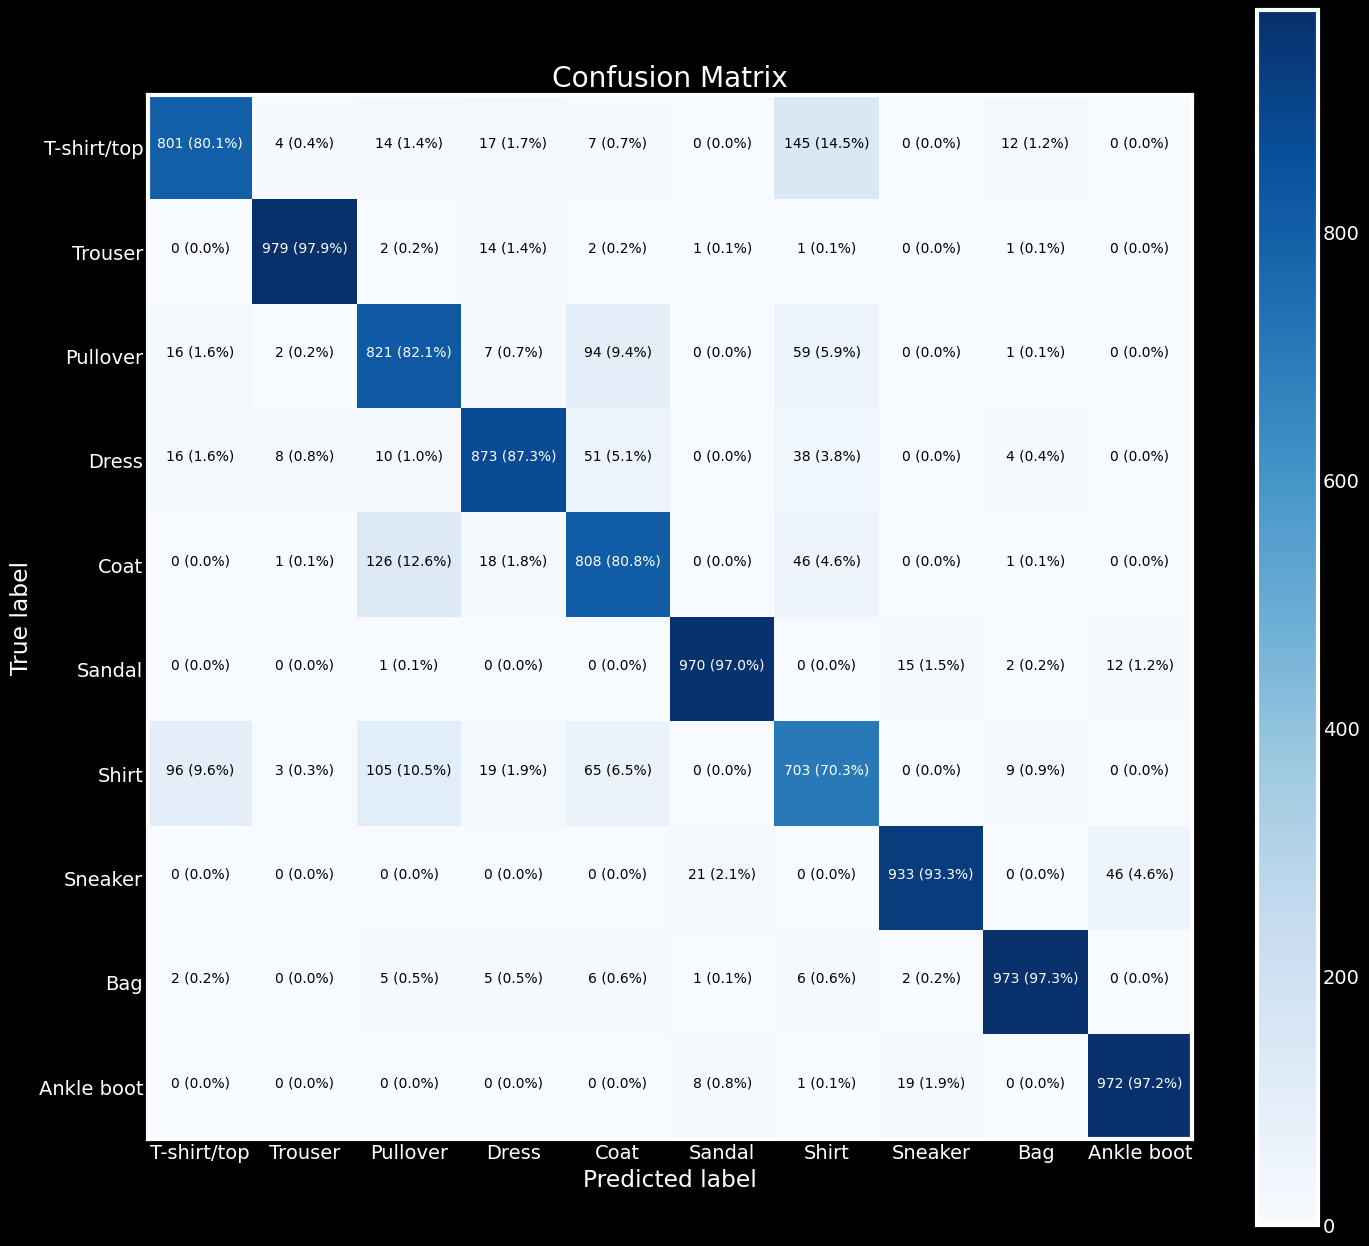

In [ ]:
# Plot confusion matrix (your original code)
import seaborn as sns
import matplotlib.pyplot as plt

# Apply the seaborn style before creating the plot
sns.set_style("dark")

# Rest of the code remains the same
plt.style.use('dark_background') #added
make_confusion_matrix(y_true=y_test,
                      y_pred=y_preds,
                      classes=class_names,
                      figsize=(15, 15),
                      text_size=10)

In [ ]:
# Predictions for new samples (your original code)
X_new = X_test[:5]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 1.  ],
       [0.  , 0.  , 0.99, 0.  , 0.01, 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.25, 0.  , 0.05, 0.  , 0.01, 0.  , 0.69, 0.  , 0.  , 0.  ]],
      dtype=float32)

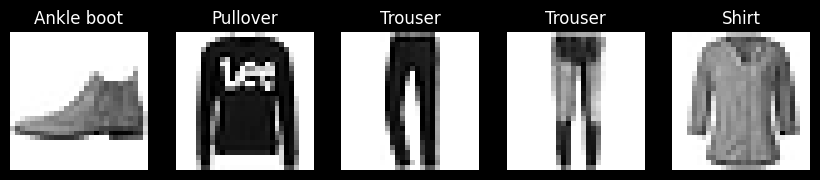

In [ ]:
# Display sample test images (your original code)
y_new = y_test[:5]
plt.figure(figsize=(9.2, 4.4))
for index, image in enumerate(X_new):
    plt.subplot(1, 5, index + 1)
    plt.imshow(image, cmap="binary", interpolation="nearest")
    plt.axis('off')
    plt.title(class_names[y_test[index]], fontsize=12)
plt.subplots_adjust(wspace=0.2, hspace=0.5)
plt.show()